In [ ]:
""" 
STORING CSV INTO MONGO AND CREATING A DFF AND DF, RETRIEVING FROM MONGO
"""

from pymongo import MongoClient
import dask.dataframe as dd
import dask.bag as bag
from dask_mongo import to_mongo, read_mongo
import pandas as pd
import dask_mongo

# Host uri for connecting to the MongoDB
host_uri = "HIDDEN"

# Storing the CSV into a DASK DataFrame
ddf = dd.read_csv("Hotel_Reviews.csv")

# Transforming the DataFrame into a DASK Bag
b = bag.from_delayed(
    ddf.map_partitions(lambda x: x.to_dict(orient="records")).to_delayed()
)

# Storing the DASK Bag to MongoDB
to_mongo(
    b,
    connection_kwargs={"host": host_uri},
    database="sentiment_analysis",
    collection="reviews"
) 

# Read into a Dask Bag from Mongo database
b = dask_mongo.read_mongo(
    connection_kwargs={"host": host_uri},
    database="sentiment_analysis",
    collection="reviews",
    chunksize=2
)

# Transforming the DASK Bag into a DASK DataFrame
ddf = b.to_dataframe()

# Transforming the DASK Bag into a Pandas DataFrame
dfOriginal = ddf.compute()

# Initializing a Mongo Client for database connection
client = MongoClient("HIDDEN")

# Choosing the right database for fetching the data
db = client.sentiment_analysis

# Choosing the right collection for fetching the data
collection = db.reviews

# Fetching the data from the collection, storing it into a list and then into a Pandas DataFrame
originalDF = pd.DataFrame(list(collection.find()))

""" 
STORING CSV INTO MONGO AND CREATING A DFF AND DF, RETRIEVING FROM MONGO
"""

' \nSTORING CSV INTO MONGO AND CREATING A DFF AND DF, RETRIEVING FROM MONGO\n'

                                                 _id  \
0  {'Hotel_Name': 'Britannia International Hotel ...   
1              {'Hotel_Name': 'Strand Palace Hotel'}   
2  {'Hotel_Name': 'Park Plaza Westminster Bridge ...   
3  {'Hotel_Name': 'Copthorne Tara Hotel London Ke...   
4  {'Hotel_Name': 'DoubleTree by Hilton Hotel Lon...   
5    {'Hotel_Name': 'Grand Royale London Hyde Park'}   
6    {'Hotel_Name': 'Holiday Inn London Kensington'}   
7          {'Hotel_Name': 'Hilton London Metropole'}   
8  {'Hotel_Name': 'Millennium Gloucester Hotel Lo...   
9   {'Hotel_Name': 'Intercontinental London The O2'}   

                                          Hotel_Name  \
0         Britannia International Hotel Canary Wharf   
1                                Strand Palace Hotel   
2               Park Plaza Westminster Bridge London   
3             Copthorne Tara Hotel London Kensington   
4  DoubleTree by Hilton Hotel London Tower of London   
5                      Grand Royale London Hyde

' \nAGGREGATE FUNCTION, DATA FROM MONGODB \n'

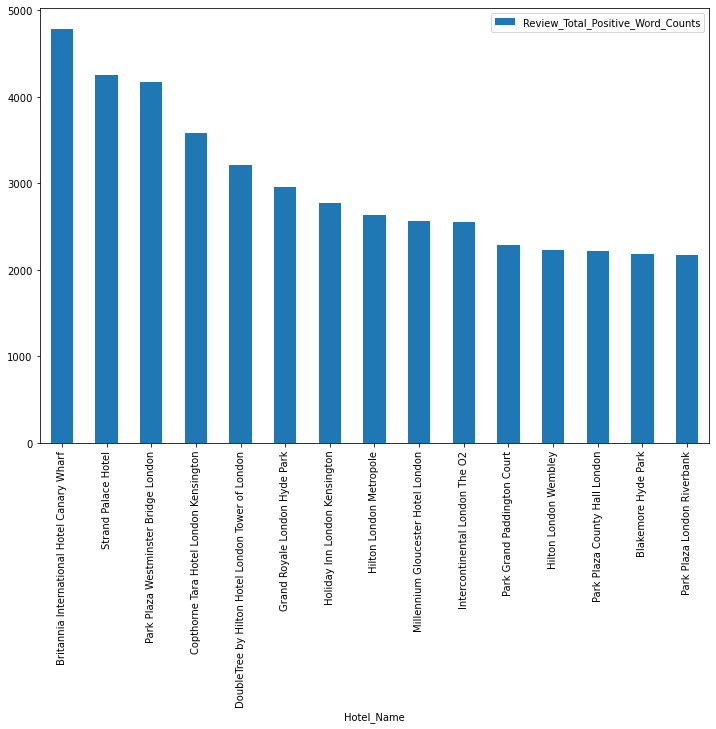

In [2]:
""" 
AGGREGATE FUNCTION, DATA FROM MONGODB 
"""
#TODO DLO & MongoCode folder for extra snippets, mapreduce etc

# Using an aggregate function to choose the right columns, deciding how to group it, then sorting out the rows
match={ "$group" : {
                "_id" : {
                    "Hotel_Name" : "$Hotel_Name"
                }, 
                "Number" : {
                    "$sum" : 1
                }
            }
        }
group={"$project" : {
                        "Hotel_Name" : "$_id.Hotel_Name",
                        "Review_Total_Positive_Word_Counts" : "$Number"
            }
        }
sort={"$sort":{ "Review_Total_Positive_Word_Counts":-1}} 

# Building a pipeline out of the aggregate function
pipeline=[match, group, sort]

# Using the pipeline to call the aggregate functions and storing the results in a variable
result = db.reviews.aggregate(pipeline) 

# Storing the result into a list
source=list(result)

# Transforming the list into a Pandas DataFrame
resultDf=pd.DataFrame(source)

print(resultDf.head(10))

# Plotting the DataFrame and storing it into a variable
plot = resultDf[:15].plot.bar(x="Hotel_Name",y="Review_Total_Positive_Word_Counts", figsize=(12, 8))

""" 
AGGREGATE FUNCTION, DATA FROM MONGODB 
"""

In [3]:
""" 
DASK
"""

from dask.dataframe import from_pandas

# Extracting only the review columns from the Dask DataFrame into its own DataFrame
reviewsDF = ddf[['Negative_Review','Positive_Review']]

# Storing the Positive reviews into its own and the negative review into its own DataFrame
posReviews = reviewsDF[['Positive_Review']]
negReviews = reviewsDF[['Negative_Review']]

# Renaming the columns so they can later be merged
posReviews=posReviews.rename(columns={"Positive_Review": "Review"})
negReviews=negReviews.rename(columns={"Negative_Review": "Review"})
 
# Assigning a label for positive and negative reviews, 1 and 0
posReviews=posReviews.assign(Positive=1)  
negReviews=negReviews.assign(Positive=0)

# Appending the negative reviews to positive reviews and combining them into the same DataFrame
reviews = negReviews.append(posReviews)

# Shuffling the data
reviews = reviews.shuffle(on=["Positive","Review"],compute=True)
reviews = reviews.reset_index(drop=True)
reviews = reviews.sample(frac=1)

# Transforming from DASK DF to Pandas DF
df = reviews.compute()

print(df)

""" 
DASK
"""

                                                  Review  Positive
43542   The rooms carpet is smelly The toilets are di...         0
93473                    Room was perfect staff friendly         1
64882   Staff treated us like we were some weird peop...         0
65232   instructions for the expresso machine would b...         0
82002   Bed just wrapped its arms around you the brea...         1
...                                                  ...       ...
35959   Good location for getting around London Aweso...         1
20710   Great location only 2 min walk to stephenplat...         1
2554                                             All ok          0
622     A bit far from city centre but by tram 25 min...         0
94638                                          Location          1

[1031476 rows x 2 columns]


' \nDASK\n'

In [4]:
""" 
WRITING OWN REVIEWS FOR THE DATAFRAME
"""

print(df)

# Writing own reviews into variables
Review1 = "Staying in this hotel made me sick for two weeks, still have not recovered"
Review2 = "Positively surprised of the service I received. I especially liked the front desk clerks"
Review3 = "As expected. Nothing fancy but not too bad either. Would recommend for bigger families. Not gonna stay again though"

#Storing the reviews intoa dict
first = { "Review": Review1, "Positive": 0 }
second = { "Review": Review2,  "Positive": 1 }
third = { "Review": Review3,  "Positive": 0 }

# Creating a list of all the reviews
allReviews = [first,second,third]

# Storing the reviews into a Pandas DataFrame
ownReviewsDF = pd.DataFrame(allReviews)

# Transforming the Pandas DataFrame into a DASK DataFrame
ddf = from_pandas(ownReviewsDF, npartitions=3)

# Combining the earlier DataFrame with the own reviews DataFrame
reviews = ddf.append(reviews)

# Shuffling the DataFrame again
reviews = reviews.shuffle(on=["Positive","Review"],compute=True)
reviews = reviews.reset_index(drop=True)
reviews = reviews.sample(frac=1)

# Transforming into a Pandas DataFrame
dfLabeled = reviews.compute()
print(dfLabeled)

""" 
WRITING OWN REVIEWS FOR THE DATAFRAME
"""

                                                  Review  Positive
43542   The rooms carpet is smelly The toilets are di...         0
93473                    Room was perfect staff friendly         1
64882   Staff treated us like we were some weird peop...         0
65232   instructions for the expresso machine would b...         0
82002   Bed just wrapped its arms around you the brea...         1
...                                                  ...       ...
35959   Good location for getting around London Aweso...         1
20710   Great location only 2 min walk to stephenplat...         1
2554                                             All ok          0
622     A bit far from city centre but by tram 25 min...         0
94638                                          Location          1

[1031476 rows x 2 columns]
                                                   Review  Positive
50076    Noisey on second night due to guests in other...         0
59089    Staff was helpful but n

' \nWRITING OWN REVIEWS FOR THE DATAFRAME\n'

In [5]:
""" 
CLEANING THE DATAFRAME DATA, Pandas + DASK
"""

import re
import time
import dask.dataframe as ddf

# Timing how long it takes to process cleaning the data with DASK and without it, starting the time
t0 = time.time()

# Function for removing the special characters from the reviews
def remove_specials(text):
    return re.sub('\W+', ' ', text)

# The main function, mapping by lowercasing the text, calling the function to remove the special characters, then removing the reviews less than 3 words long
def clean_text(df):
    df["Review"] = df.Review.map(lambda text:text.lower()).map(remove_specials).apply(lambda i: ' '.join(filter(lambda j: len(j) > 3, i.split())))
    return df   

# Calling the main function to clean the dataframe
dfLabeled = clean_text(dfLabeled)

# Taking the time again after processing
t1 = time.time()

# Printing out the result by calculating the starting and stopping times
print("Time to process without Dask {}".format(t1-t0))

# Storing the cleaned dataframe into a DASK DF
dask_dataframe = ddf.from_pandas(dfLabeled, npartitions=6)

# Taking time again, this time for DASK
t0 = time.time()

# Calling the function with DASK DF and storing the resulted cleaned data into a variable DF
result = dask_dataframe.map_partitions(clean_text, meta=df)

# Taking time again now after processing
t1 = time.time()

# Transforming into Pandas DF
df = result.compute()

# Printing out the results with speed
print("Time to process with Dask {}".format(t1-t0))

# Doing further cleaning with the data inside DASK DF, getting rid of unnecessary reviews
df = df[(df["Review"]!="negative")]
df = df[(df["Review"]!="nothing")]
df = df[(df["Review"]!="location")]
df = df[(df["Review"]!="positive")]
df = df[(df["Review"]!="please above")]

# Renaming the DF
dfLabeled = df
print(dfLabeled)

""" 
CLEANING THE DATAFRAME DATA, Pandas + DASK
"""

Time to process without Dask 12.853787422180176
Time to process with Dask 0.45953798294067383
                                                   Review  Positive
0       positively surprised service received especial...         1
0       thin walls could hear everything from room ups...         0
0                  single room extremely small restaurant         0
0       rooms carpet smelly toilets dirty lobby entran...         0
0       expected nothing fancy either would recommend ...         0
...                                                   ...       ...
248807  excellent location exploring london very good ...         1
248809  room small called queen room room just compute...         0
248832  maybe more variety cheese salami different thi...         0
248834                clean high standard excellent hotel         0
248840                            very noisy unable sleep         0

[829233 rows x 2 columns]


' \nCLEANING THE DATAFRAME DATA, Pandas + DASK\n'

The distribution of positive and negative reviews: 
1    0.559586
0    0.440414
Name: Positive, dtype: float64


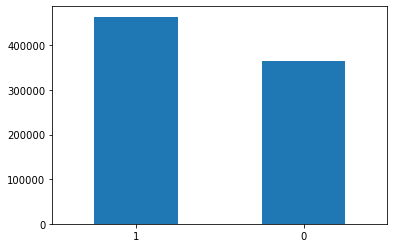

' \nCREATING A BARCHART AND A WORDCLOUD\n'

In [6]:
""" 
CREATING A BARCHART AND A WORDCLOUD
"""

from wordcloud import WordCloud
import matplotlib.pyplot as plt
from nltk.corpus import stopwords

# Writing common stop words myself that the stopwords library doesnt include on its own
swords = ["based","need","could","range","offer","fairly","nights","attentiv","putney","fri","pool","f","booking","tube","com","Length","the","at","cl","i","dtype","object","o","Review","and","th","it","Name","our","dad",
"seating","we","shuttle","access","wit","or","of","ran","for","my","went","testing","was","after","to","very","but","with","without","late",
"grea","robes","no","king","slept","work","would","had","are","not","one","r","bed","a","all","plugs","though","t","on","previo","in","didn","junior","from","were","help","even"]

# Combining the stopwords library's stopwords with own stopwords
swords = swords + stopwords.words('english')

# Creating a function that gets a dataframe column (reviews) as a parameter and what returns a wordcloud
def show_wordcloud(data):
    wordcloud = WordCloud(
        stopwords = swords,
        background_color = 'white',
        max_words = 50,
        max_font_size = 40,
        scale = 3,
        random_state = 42,
        min_word_length = 3
    ).generate(str(data))

    plt.axis('off')
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.show()

# Storing the positive reviews into its own and negative into its own dataframes
dfPos = df[df['Positive'] == 1]
dfNeg = df[df['Positive'] == 0]



print("The distribution of positive and negative reviews: ") 

# Count the distribution of positive and negative reviews and print it
print(df["Positive"].value_counts(normalize = True))

# Create a bar plot based on the pos/neg distribution and display the bar
ax = df['Positive'].value_counts().plot.bar(rot=0)
plt.show()

# Extracting the negative reviews ( choosing only the reviews from the neg DF ) and generating a wordcloud based on it
negText = dfNeg["Review"].values
negWordCloud = WordCloud(stopwords=swords,background_color='white').generate(str(negText))

# Same for positive reviews
posText = dfPos["Review"].values
posWordCloud = WordCloud(stopwords=swords,background_color='white').generate(str(posText))

# Same for both negative and positive combined
posAndNegText = df["Review"].values
posAndNegWordCloud = WordCloud(stopwords=swords,background_color='white').generate(str(posAndNegText))

""" 
CREATING A BARCHART AND A WORDCLOUD
"""

In [43]:
""" 
VISUALISATIONS / DASH DASHBOARD 
"""

# (most make a scatterplot of hotels on the geographical map as overview, filter on rating or region and show all data of the hotel in Details on Demand), 
# You can also look at the interesting things about reviewers or the countries of origin,
# maybe a heatmap between origin of reviewers and country of the hotel with rating or volume as value

import dash
import dash_core_components as dcc
import dash_html_components as html
import plotly.graph_objs as go
import plotly.express as px
from dash.dependencies import Input, Output

# Initializing a Dash app
app = dash.Dash(__name__)

# Choosing only the first 200 000 rows from the df for performance and development purposes
df = originalDF.head(200000)

# Filtering out other rows than the ones which hotel locates in Paris, creating a new DF
onlyParis=df[df['Hotel_Address'].str.contains('Paris') == True]

# Dropping the duplicates from the created DF
hotelsdf = onlyParis.drop_duplicates(subset=['Hotel_Name'])

# Creating and storing a scatterplot into a variable
scatterplot = px.scatter(hotelsdf, y="Reviewer_Score", x="Reviewer_Nationality")

# Setting the needed access token for using the Mapbox API, generated on their website, for px to use
px.set_mapbox_access_token("pk.eyJ1IjoiYXJ0dHVhIiwiYSI6ImNsNGx0MGpjMTFid2EzanBmYm8xY25mbjEifQ.23I_Cdnze1SbuMDPVjkAEw")

# Creating a Mapbox map with px
fig = px.scatter_mapbox(hotelsdf, lat="lat", lon="lng", color="Hotel_Name", hover_name="Hotel_Name",
                  color_continuous_scale=px.colors.cyclical.IceFire, size_max=15, zoom=10)

# Creating a bar plot
bar = px.bar(resultDf[:15], x='Hotel_Name', y='Review_Total_Positive_Word_Counts')

# Creating a WordCloud for each dataframe, neg, pos and all reviews
negFig = px.imshow(negWordCloud)
posFig = px.imshow(posWordCloud)
posNegFig = px.imshow(posAndNegWordCloud)

# Calling app layout and adding HTML elements into it
app.layout = html.Div([
    # Header
    html.H1('Hotel Reviews Dashboard'),
    # Using Dash Core Components for creating a tab for each figure
    dcc.Tabs([
        dcc.Tab(label='Scatterplot', children=[
            dcc.Graph(id="graph",
                figure=scatterplot
            )
        ]),
        dcc.Tab(label='Map', children=[
            dcc.Graph(id="map",
                figure=fig
            )
        ]),
         dcc.Tab(label='Bar', children=[
            dcc.Graph(id="bar",
                figure=bar
            )
        ]),
        dcc.Tab(label='WordCloud, Negative Reviews', children=[
            dcc.Graph(id="wordcloud",
                figure=negFig
            )
        ]),
        dcc.Tab(label='WordCloud, Positive Reviews', children=[
            dcc.Graph(id="wordcloud2",
                figure=posFig
            )
        ]),
        dcc.Tab(label='WordCloud, All Reviews', children=[
            dcc.Graph(id="wordcloud3",
                figure=posNegFig
            )
        ])
    ]),
    # Lastly, showing the content section
    html.Div(id='tabs-content')
])

# Using this function to initialize and run the server
if __name__ == '__main__':
    app.run_server(debug=True, use_reloader=False)

""" 
VISUALISATIONS / DASH DASHBOARD 
"""

Dash is running on http://127.0.0.1:8050/

Dash is running on http://127.0.0.1:8050/

Dash is running on http://127.0.0.1:8050/

 * Serving Flask app "__main__" (lazy loading)
 * Environment: production
   Use a production WSGI server instead.
 * Debug mode: on


In [8]:
""" 
TWEAKING, DASK, Pandas, GRIDSEARCH
"""

from dask_ml.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
import joblib
import dask.distributed
from dask.distributed import Client
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC

# Initializing a vectorizer which is used to transform the reviews into numerical form while doing further cleaning
vectorizer = TfidfVectorizer(min_df=20, max_df=0.95, ngram_range=(1,1), stop_words='english', strip_accents='ascii',lowercase=True)

# Choosing only small part of the rows for performance and development purposes
df = dfLabeled
df = df.head(10000)

# Dividing the DF data into their own variables, running the reviews through the vectorizer and storing into own variable
X = vectorizer.fit_transform(df["Review"])
# Storing the labels into their own variable
y = df["Positive"]


# Generating/splitting into training and testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

# initializing, fitting and scoring a SVC model
model = SVC(random_state=0)
model.fit(X_train, y_train)
print("SVC model score, random_state=0: ",model.score(X, y))

# Re-initializing, fitting and scoring the model but with different parameters   !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!! X,Y, before it was x_ttrain y_train
model = SVC(C=0.00001, shrinking=False, random_state=0)
model.fit(X_train, y_train)
print("SVC model score, C=0.00001, shrinking=False, random_state=0: ",model.score(X, y))

# Creating an estimator for SVC for using with the GridSearchCV for hyperparameter tuning
estimator = SVC(gamma='auto', random_state=0, probability=True)

# Creating a parameter grid, which values will be tested and tuned
param_grid = {
    'C': [0.001, 0.1, 1.0, 10.0],
    'kernel': ['rbf', 'poly'],
}

# Intializing a GridSearch variable and fitting the data in it
grid_search = GridSearchCV(estimator, param_grid, verbose=2, cv=2)

#TODO before was X,y
grid_search.fit(X_train, y_train)

# Printing out the best params and best score
print("Grid search best params Pandas: ", grid_search.best_params_)
print("Grid search best score Pandas: ", grid_search.best_score_)

# Re-initializing GridSearch but with different parameters and printing out the time used to fit the GridSearch
grid_search = GridSearchCV(estimator, param_grid, verbose=2, cv=2, n_jobs=-1)
t0 = time.time()
grid_search.fit(X, y)
t1 = time.time()

# Printing out the results
print("Time to process grid_search.fit with Pandas: {}".format(t1-t0))
print("Grid search best params without DASK: ", grid_search.best_params_)
print("Grid search best score without DASK: ", grid_search.best_score_)

# Initializing a DASK client for parallel computing and comparing the results
c = dask.distributed.Client(processes=False)

# Re-generating a parameter grid 
param_grid = {
    'C': [0.001, 0.1, 1.0, 10.0],
    'kernel': ['rbf', 'poly']
}

# Initializing the GridSearch again
grid_search = GridSearchCV(estimator, param_grid, verbose=2, cv=2, n_jobs=-1)

# Counting the time before fitting and after fitting the GridSearch
t2 = time.time()
with joblib.parallel_backend("dask"):
    grid_search.fit(X, y)
t3 = time.time()

# Printing out the results
print("Time to process grid_search.fit with DASK: {}".format(t3-t2))
print("Grid search best params DASK: ", grid_search.best_params_)
print("Grid search best score DASK: ", grid_search.best_score_)

""" 
TWEAKING, DASK, Pandas, GRIDSEARCH
"""

SVC model score, random_state=0:  0.9491
SVC model score, C=0.00001, shrinking=False, random_state=0:  0.5568
Fitting 2 folds for each of 8 candidates, totalling 16 fits
[CV] END ................................C=0.001, kernel=rbf; total time=  15.1s
[CV] END ................................C=0.001, kernel=rbf; total time=  20.4s
[CV] END ...............................C=0.001, kernel=poly; total time=  16.0s
[CV] END ...............................C=0.001, kernel=poly; total time=  15.0s
[CV] END ..................................C=0.1, kernel=rbf; total time=  16.6s
[CV] END ..................................C=0.1, kernel=rbf; total time=  10.7s
[CV] END .................................C=0.1, kernel=poly; total time=   7.3s
[CV] END .................................C=0.1, kernel=poly; total time=   9.0s
[CV] END ..................................C=1.0, kernel=rbf; total time=   9.4s
[CV] END ..................................C=1.0, kernel=rbf; total time=   8.9s
[CV] END ...........

' \nTWEAKING, DASK, Pandas, GRIDSEARCH\n'

In [41]:
""" 
DASK ML VS SKLEARN 
"""

from sklearn.linear_model import LogisticRegression as skLog


logReg = skLog()
t4 = time.time()
logReg.fit(X,y)
t5 = time.time()
print("sklearn Logistic Regression fitting time: {}".format(t5-t4))

from sklearn.naive_bayes import GaussianNB

GNB = GaussianNB()
t4 = time.time()
GNB.fit(X.toarray(),y)
t5 = time.time()
print("sklearn GaussianNB: {}".format(t5-t4))

from dask_ml.naive_bayes import GaussianNB

GNB = GaussianNB()
t4 = time.time()
GNB.fit(X.toarray(),y)
t5 = time.time()
print("Dask GaussianNB: {}".format(t5-t4))

from dask_ml.linear_model import LogisticRegression as daskLog

logRegDask=daskLog()
t6 = time.time()
logRegDask.fit(X.toarray(),y)
t7 = time.time()
print("Dask Logistic Regression fitting time: {}".format(t7-t6))

""" 
DASK ML VS SKLEARN 
"""

sklearn Logistic Regression fitting time: 0.16200041770935059
sklearn GaussianNB: 0.31200170516967773
Dask GaussianNB: 0.2557082176208496
Dask Logistic Regression fitting time: 18.086397171020508


' \nDASK ML VS SKLEARN \n'

In [14]:

import matplotlib.pyplot as plt
from keras_preprocessing.sequence import pad_sequences
from keras.preprocessing.text import Tokenizer
from keras.models import Sequential
from keras.layers.core import Activation, Dropout, Dense
from keras.layers import Flatten
from tensorflow.keras.layers import Embedding
from sklearn.model_selection import train_test_split
from numpy import array
from numpy import asarray
from numpy import zeros


X = reviews["Review"].compute()
y = reviews["Positive"].compute().head(1031479)


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

max_words=5000

tokenizer = Tokenizer(num_words=max_words)

tokenizer.fit_on_texts(X_train)

X_train_tok = tokenizer.texts_to_sequences(X_train)
X_test_tok = tokenizer.texts_to_sequences(X_test)

maxlen = 100 

X_train_pad = pad_sequences(X_train_tok, padding='post', maxlen=maxlen)
X_test_pad = pad_sequences(X_test_tok, padding='post', maxlen=maxlen)

# X_train[30]
# X_train_tok[30]
# X_train_pad[10]

# Adding 1 because of reserved 0 index
vocab_size = len(tokenizer.word_index) + 1

glovefile ='glove.6B.100d.txt'
embeddings_dictionary = dict()
glove_file = open(glovefile, encoding="utf8")

for line in glove_file:
    records = line.split()
    word = records[0]
    vector_dimensions = asarray(records[1:], dtype='float32')
    embeddings_dictionary [word] = vector_dimensions
glove_file.close()

embedding_matrix = zeros((vocab_size, 100))
for word, index in tokenizer.word_index.items():
    embedding_vector = embeddings_dictionary.get(word)
    if embedding_vector is not None:
        embedding_matrix[index] = embedding_vector

c:\Users\Arttu\anaconda3\lib\site-packages\keras\optimizers\optimizer_v2\adam.py:110: UserWarning:

The `lr` argument is deprecated, use `learning_rate` instead.



Epoch 1/6
5158/5158 [==============================] - 33s 6ms/step - loss: 0.2337 - acc: 0.9119 - val_loss: 0.2108 - val_acc: 0.9212
Epoch 2/6
5158/5158 [==============================] - 30s 6ms/step - loss: 0.2081 - acc: 0.9224 - val_loss: 0.2118 - val_acc: 0.9228
Epoch 3/6
5158/5158 [==============================] - 32s 6ms/step - loss: 0.2050 - acc: 0.9239 - val_loss: 0.2119 - val_acc: 0.9221
Epoch 4/6
5158/5158 [==============================] - 26s 5ms/step - loss: 0.2035 - acc: 0.9246 - val_loss: 0.2133 - val_acc: 0.9234
Epoch 5/6
5158/5158 [==============================] - 27s 5ms/step - loss: 0.2028 - acc: 0.9248 - val_loss: 0.2119 - val_acc: 0.9226
Epoch 6/6
6447/6447 [==============================] - 15s 2ms/step - loss: 0.2089 - acc: 0.9227
model summary:
Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_4 (Embedding)     (None, 100, 100)          7234300  

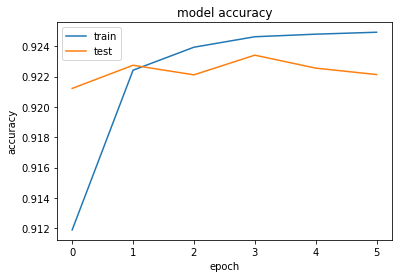

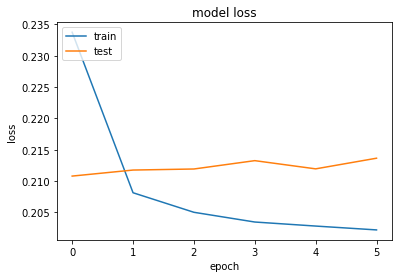

' \nANN \n'

In [16]:
""" 
ANN 
"""

import keras
from keras import backend as K
from matplotlib import pyplot as plt
from keras.models import Sequential
from keras.layers import Flatten, Dense, Embedding

# # Tweaking the learning rate for the optimizer
K.set_value(model.optimizer.learning_rate, 0.0005)
adamLr = keras.optimizers.Adam(lr=0.0005)

# Creating the ANN model

# Initializing the model by creating a sequential model
model = Sequential()

# Initializing an embedding layer
embedding_layer = Embedding(vocab_size, 100, weights=[embedding_matrix], input_length=maxlen, trainable=False)

# Adding the embedding layer to the model
model.add(embedding_layer)

# Adding the flattening layer to the model
model.add(Flatten())

# Adding dense layer to the model, using sigmoid activation function
model.add(Dense(1, activation='sigmoid'))

# Compiling the model
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['acc'])

# Fit the model
history = model.fit(X_train_pad, y_train, batch_size=128, epochs=6, verbose=1, validation_split=0.2)

# Final evaluation of the model
score = model.evaluate(X_test_pad, y_test, verbose=1)

# Printing the final results
print("model summary:")
print(model.summary())
print(model.metrics_names)
print("Test Score:", score[0])
print("Test Accuracy:", score[1])


# Plotting the results with pyplot
plt.plot(history.history['acc'])
plt.plot(history.history['val_acc'])

plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train','test'], loc='upper left')
plt.show()

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train','test'], loc='upper left')
plt.show()

""" 
ANN 
"""

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_5 (Embedding)     (None, 100, 32)           2314976   
                                                                 
 conv1d_1 (Conv1D)           (None, 96, 1)             161       
                                                                 
 global_max_pooling1d_1 (Glo  (None, 1)                0         
 balMaxPooling1D)                                                
                                                                 
 dense_5 (Dense)             (None, 1)                 2         
                                                                 
Total params: 2,315,139
Trainable params: 2,315,139
Non-trainable params: 0
_________________________________________________________________
None
Epoch 1/3
5158/5158 [==============================] - 271s 52ms/step - loss: 0.2893 - acc: 0.8995 - val_

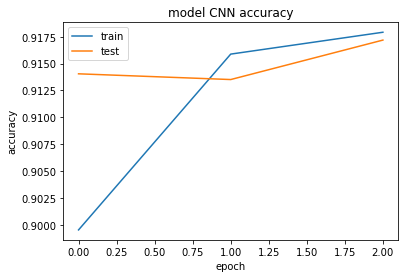

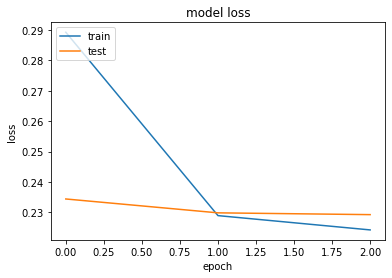

' \nCNN \n'

In [17]:
""" 
CNN
"""

from keras.layers.convolutional import Conv1D
from keras.layers import GlobalMaxPooling1D

# Creating the model
modelCNN = Sequential()

# Adding embedding layer to the model
modelCNN.add(Embedding(vocab_size, 32, input_length=maxlen))


# The text is 1 dimensional, thus adding Conv1D layer, the kernel in this case is a vector of length 5
modelCNN.add(Conv1D(1, 5, activation='relu'))

# The pooling layer in this case is also 1 dimensional
modelCNN.add(GlobalMaxPooling1D())

# Adding a dense layer to the model
modelCNN.add(Dense(1, activation='sigmoid'))

# Compiling the model
modelCNN.compile(loss='binary_crossentropy', optimizer='adam', metrics=['acc'])

# Printing out the summary
print(modelCNN.summary())

# Fitting the model
history = modelCNN.fit(X_train_pad, y_train, batch_size=128, epochs=3, verbose=1, validation_split=0.2)

# Scoring and evaluating the model
score = modelCNN.evaluate(X_test_pad, y_test, verbose=1)

# Printing out the results
print("Test Score:", score[0])
print("Test Accuracy:", score[1])

# Plotting the results
plt.plot(history.history['acc'])
plt.plot(history.history['val_acc'])

plt.title('model CNN accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train','test'], loc='upper left')
plt.show()

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train','test'], loc='upper left')
plt.show()

""" 
CNN 
"""

Model: "sequential_6"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_6 (Embedding)     (None, 100, 10)           723430    
                                                                 
 lstm_1 (LSTM)               (None, 67)                20904     
                                                                 
 dense_6 (Dense)             (None, 1)                 68        
                                                                 
Total params: 744,402
Trainable params: 744,402
Non-trainable params: 0
_________________________________________________________________
None
[[  1  10  28 ...   0   0   0]
 [ 56   0   0 ...   0   0   0]
 [219  25  57 ...   0   0   0]
 ...
 [  1   6   3 ...   0   0   0]
 [ 49   6   3 ...   0   0   0]
 [  1  59 287 ...   0   0   0]]
36463     1
80773     0
27392     1
66188     1
106474    0
         ..
9663      0
77782     0
38948     1
39572  

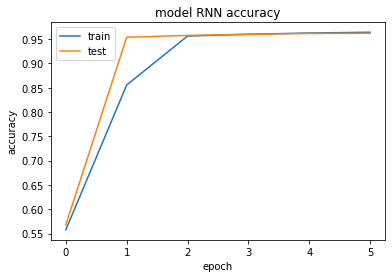

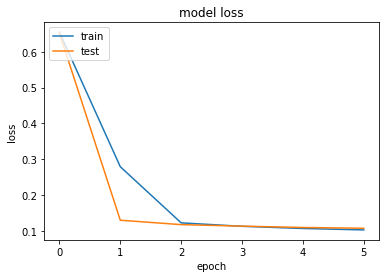

' \nRNN / LSTM \n'

In [18]:
""" 
RNN / LSTM
"""

from tensorflow.keras.layers import LSTM


# Tweaking the hyperparameter learning rate
# K.set_value(model.optimizer.learning_rate, 0.0001)
# adamLr = keras.optimizers.Adam(lr=0.0001)

# Creating the sequential model
modelRNN = keras.Sequential()

# Adding an embedding layer to the model
modelRNN.add(Embedding(vocab_size, 10, input_length=maxlen))

# Adding LSTM layer to the model
modelRNN.add(LSTM(67))

# Adding a dense layer to the model, using sigmoid activation function 
modelRNN.add(Dense(1, activation='sigmoid'))

# Compiling the model
modelRNN.compile(loss='binary_crossentropy', optimizer='adam', metrics=['acc'])

# Printing out the summary
print(modelRNN.summary())

# Printing out the data for checking
print(X_train_pad)
print(y_train)

# Fitting the model
history = modelRNN.fit(X_train_pad, y_train, batch_size=128, epochs=6, verbose=1, validation_split=0.2)

# Scoring and evaluating the model
score = modelRNN.evaluate(X_test_pad, y_test, verbose=1)

# Printing out the results
print("Test Score:", score[0])
print("Test Accuracy:", score[1])

# Plotting the results
plt.plot(history.history['acc'])
plt.plot(history.history['val_acc'])

plt.title('model RNN accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train','test'], loc = 'upper left')
plt.show()

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train','test'], loc='upper left')
plt.show()

""" 
RNN / LSTM 
"""